In [1]:
# @title Imports {vertical-output: true}

import collections
import os

from etils import epath
from IPython.display import HTML
import matplotlib.pyplot as plt
from ml_collections import config_dict
import numpy as np
import tensorflow as tf
import tqdm

# perch-hoplite: the agile modeling workflow.
from perch_hoplite.agile import audio_loader
from perch_hoplite.agile import classifier
from perch_hoplite.agile import classifier_data
from perch_hoplite.agile import colab_utils
from perch_hoplite.agile import embed
from perch_hoplite.agile import embedding_display
from perch_hoplite.agile import ingest_annotations
from perch_hoplite.agile import source_info
from perch_hoplite.db import brutalism
from perch_hoplite.db import interface
from perch_hoplite.db import score_functions
from perch_hoplite.db import search_results
from perch_hoplite.zoo import model_configs

print('TensorFlow version :', tf.__version__)
print('NumPy version      :', np.__version__)

# A GPU makes the embedding step considerably faster. Every other step in this
# tutorial is quick on CPU, so a CPU-only runtime is perfectly usable.
gpus = tf.config.list_physical_devices('GPU')
if gpus:
  print(f'GPU available      : yes ({len(gpus)} device(s))')
else:
  print('GPU available      : no (CPU only - this is fine for this tutorial)')

TensorFlow version : 2.21.0
NumPy version      : 2.5.4
GPU available      : no (CPU only - this is fine for this tutorial)


In [2]:
from perch_hoplite.db import sqlite_usearch_impl

db_path = './content/osa_db'
db = sqlite_usearch_impl.SQLiteUSearchDB.create(db_path=db_path)

configs = config_dict.ConfigDict(db.get_metadata(None))

configs = source_info.AudioSources.from_config_dict(config=configs.audio_sources)
type(configs)
configs


AudioSources(audio_globs=(AudioSourceConfig(dataset_name='silencio', base_path='./data/audio', file_glob='*/*.wav', min_audio_len_s=1.0, target_sample_rate_hz=-2, shard_len_s=60.0, max_shards_per_file=None), AudioSourceConfig(dataset_name='grillos', base_path='./data/grillos/', file_glob='*/*.wav', min_audio_len_s=1.0, target_sample_rate_hz=-2, shard_len_s=60.0, max_shards_per_file=None), AudioSourceConfig(dataset_name='SWIFT', base_path='./data/SWIFT/', file_glob='*/*.wav', min_audio_len_s=1.0, target_sample_rate_hz=-2, shard_len_s=60.0, max_shards_per_file=None)))

In [3]:
# @title Load the pre-trained embedding model {vertical-output: true}

# Like the original version of this tutorial, we use one model throughout:
# Perch v8, the direct successor to the v4 model the 2023 version loaded
# from TFHub. perch-hoplite also supports other embedding models (Perch 2.0,
# BirdNET, SurfPerch, ...), but embeddings from different models are not
# comparable, so each model needs its own database built from scratch.
model_choice = 'perch_8'

preset_info = model_configs.get_preset_model_config(model_choice)

print(f'Preset           : {model_choice}')
print(f'Model class key  : {preset_info.model_key}')
print(f'Embedding dim    : {preset_info.embedding_dim}')
print(f'Window size (s)  : {preset_info.model_config.window_size_s}')
print(f'Hop size (s)     : {preset_info.model_config.hop_size_s}')
print(f'Sample rate (Hz) : {preset_info.model_config.sample_rate}')

# Convenience aliases used throughout the rest of the notebook.
SAMPLE_RATE = int(preset_info.model_config.sample_rate)
WINDOW_SIZE_S = float(preset_info.model_config.window_size_s)
HOP_SIZE_S = float(preset_info.model_config.hop_size_s)

# The model is downloaded from Kaggle Models on first use, then cached for the
# rest of the session.
print('\nLoading model (the first run downloads it from Kaggle)...')
embedding_model = preset_info.load_model()

# Smoke test: embed five seconds of silence and check the output shape.
silence = np.zeros([int(SAMPLE_RATE * WINDOW_SIZE_S)], dtype=np.float32)
test_embedding = embedding_model.embed(silence).embeddings

print('Model loaded successfully.')
print(f'Test embedding shape: {test_embedding.shape} '
      f'-> {test_embedding.shape[-1]} numbers describing '
      f'{WINDOW_SIZE_S:.0f}s of audio')

Preset           : perch_8
Model class key  : taxonomy_model_tf
Embedding dim    : 1280
Window size (s)  : 5.0
Hop size (s)     : 5.0
Sample rate (Hz) : 32000

Loading model (the first run downloads it from Kaggle)...


c:\agile\.venv\Lib\site-packages\perch_hoplite\zoo\zoo_interface.py:159: UserWarning: 'where' used without 'out', expect uninitialized memory in output. If this is intentional, use out=None.
  framed_audio = np.divide(framed_audio, peak_norm, where=(peak_norm > 0.0))


Model loaded successfully.
Test embedding shape: (1, 1, 1280) -> 1280 numbers describing 5s of audio


In [4]:
# @title Define the target label {vertical-output: true}

# @markdown The eBird species code for the Wood Thrush.
target_label = 'LEPINS'  # @param {type: 'string'}
'''
Possible target labels
SCIBOU *
DENEBR *
BOAROS *

ELAPER
ENGPUS
DENMIC
LEPFRA
'''
annotator_id = 'testing'

# Loads the audio behind a search result so we can plot and play it.
audio_filepath_loader = audio_loader.make_filepath_loader(
    audio_sources=configs,
    window_size_s=WINDOW_SIZE_S,
    sample_rate_hz=SAMPLE_RATE,
)

print('Target label :', target_label)
print('Annotator id :', annotator_id)

Target label : LEPINS
Annotator id : testing


In [5]:
# @title Load the query audio {vertical-output: true}

# @markdown `query_uri` accepts a Xeno-Canto ID (like `xc105133`), a URL, or a
# @markdown path to a local file.
query_uri = r'C:\agile\static\Leptodactylus insularum\audio\Leptodactylus insularum0.mp3'  # @param {type: 'string'}

# @markdown Where in the recording to start looking, in seconds.
query_offset_s = 0.0  # @param {type: 'number'}

query = embedding_display.QueryDisplay(
    uri=query_uri,
    offset_s=query_offset_s,
    window_size_s=WINDOW_SIZE_S,
    sample_rate_hz=SAMPLE_RATE,
)
_ = query.display_interactive()

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='offset_s', max=16.76653125)…

In [6]:
# @title Embed the query {vertical-output: true}

# Take the window selected above and run it through the embedding model.
query_audio = query.get_audio_window()
query_embedding = embedding_model.embed(query_audio).embeddings[0, 0]

print('Query audio samples :', query_audio.shape[0],
      f'({query_audio.shape[0] / SAMPLE_RATE:.1f} seconds)')
print('Query embedding     :', query_embedding.shape,
      f'-> {query_embedding.shape[0]} numbers')

c:\agile\.venv\Lib\site-packages\perch_hoplite\zoo\zoo_interface.py:159: UserWarning: 'where' used without 'out', expect uninitialized memory in output. If this is intentional, use out=None.
  framed_audio = np.divide(framed_audio, peak_norm, where=(peak_norm > 0.0))


Query audio samples : 160000 (5.0 seconds)
Query embedding     : (1280,) -> 1280 numbers


In [7]:
def filter_results(project, results, db):

    windows = [int(r.window_id) for r in results.search_results]
    embeds = [db.get_window(w) for w in windows]
    records = [db.get_recording(w.recording_id) for w in embeds]
    deploys = [db.get_deployment(w.deployment_id) for w in records]

    keep = []

    for deploy in deploys:
        if deploy.project == project:
            keep.append(True)
        else:
            keep.append(False)

    filtered = [w for w, m in zip(results, keep) if m]
    print(keep)

    return filtered

In [8]:

# @markdown Number of search results to return and display.
num_results = 25  # @param {type: 'number'}

# @markdown Leave this UNCHECKED on your first pass - it returns the closest
# @markdown matches, which is what you want when starting out. Enable it only
# @markdown after you have some positives, to hunt for harder examples.
target_sampling = False  # @param {type: 'boolean'}

# @markdown The score to aim for when target sampling is on. Read this off the
# @markdown histogram below rather than guessing - a value outside the real
# @markdown score range returns the LEAST similar clips in the corpus.
target_score = 3.0  # @param {type: 'number'}

# @markdown If checked, scan the whole database exactly. Otherwise use faster
# @markdown approximate nearest-neighbor search.
exact_search = True  # @param {type: 'boolean'}

results = db.search(
    query_embedding,
    search_list_size=num_results,
    approximate=not exact_search,
    target_score=target_score if target_sampling else None,
)

hit_scores = [r.sort_score for r in results.search_results]
print(f'Returned {len(hit_scores)} results.')
print(f'Score range : {min(hit_scores):.2f} to {max(hit_scores):.2f}')

filtered = filter_results('grillos', results, db)


print(len(filtered))





Returned 25 results.
Score range : 3.26 to 4.16
[False, True, False, False, False, False, False, False, False, True, True, True, False, False, False, True, False, False, True, False, False, True, True, False, False]
8


### <a name=choosing-target-score></a>Choosing a target score

The search also lets us look at how scores are distributed across the whole corpus. The actual numbers are hard to interpret on their own, but their *shape* is informative.

The histogram below samples scores from across the database. The bulk of it is everything that does **not** sound like your query — the ordinary background of the soundscape. Your search hits (red marks) sit out in the right tail.

Two regions of the histogram are useful, for different jobs:

* **The bulk** — everything that does not sound like your query. Set `target_score` inside the bulk (a low value) and the search returns clips that are almost all *not* the species: the fastest way to collect **negative labels**.
* **Where the tail meets the bulk** — the ambiguous cases: faint vocalizations, distant birds, calls partly masked by something else. Labeling these is worth far more per example than labeling more obvious hits, because they are what the decision boundary is actually made of.

**Try it:** read a value off the bulk, go back to the search cell, enable `target_sampling`, set `target_score` to that value, and label (and save) another round.

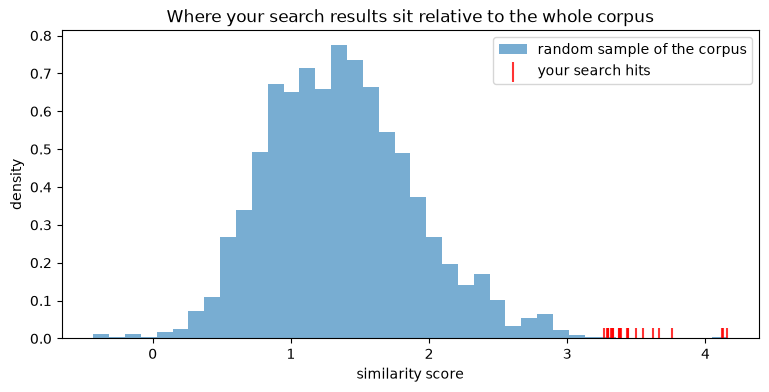

Corpus scores  : -0.43 to 4.16
Your hits      : 3.26 to 4.16


In [9]:
# @title Plot the distribution of scores {vertical-output: true}

scores = brutalism.get_random_embedding_scores(
    db,
    query_embedding,
    score_fn=score_functions.get_score_fn('dot'),
    sample_size=2048,
    rng_seed=42,
)

plt.figure(figsize=(9, 4))
plt.hist(scores, bins=40, density=True, alpha=0.6,
         label='random sample of the corpus')

#hit_scores = [r.sort_score for r in results.search_results]
plt.scatter(hit_scores, np.zeros_like(hit_scores), marker='|',
            color='r', alpha=0.8, s=200, label='your search hits')

plt.xlabel('similarity score')
plt.ylabel('density')
plt.title('Where your search results sit relative to the whole corpus')
plt.legend()
plt.show()

print(f'Corpus scores  : {scores.min():.2f} to {scores.max():.2f}')
print(f'Your hits      : {min(hit_scores):.2f} to {max(hit_scores):.2f}')

### User-in-the-loop labeling (**requires your input**)

The cell below shows each search result as:

* a **spectrogram** of the five-second window,
* an **audio player** so you can listen to it,
* the **source file**, the **offset** in seconds, its **rank**, and its similarity **score**,
* a **label button** showing the target species name.

#### How the label button works

The button **cycles through four states** each time you click it. The colour and icon tell you which state you are in:

| Clicks | State | Appearance | Recorded? |
| --- | --- | --- | --- |
| 0 | unlabeled | grey, no icon | no — ignored |
| 1 | **positive** | **green, ✚ icon** | **yes — the species is present** |
| 2 | **negative** | **orange, ➖ icon** | **yes — the species is absent** |
| 3 | uncertain | blue, ❓ icon | no — deliberately skipped |
| 4 | back to unlabeled | grey, no icon | no — ignored |

**To mark a clip as containing the species, click once so the button turns green with a ✚.** If you click past it, keep clicking — it cycles back around.

#### What to do

Listen to each result and label it:

* **Green (✚)** where you can hear the Wood Thrush.
* **Orange (➖)** where you are confident it is *not* there. This is worth doing: a confirmed negative is much stronger evidence than an unlabeled result, which the model only treats as a weak guess.
* **Leave grey** if you genuinely cannot tell. Do not guess.

**You will label in two passes, and this display serves both.** Pass one: with the plain search results, expect nearly every clip to contain the song — mark **10 or more greens**, then run the *save labels* cell below. Pass two: return to the search cell, enable `target_sampling` with a low `target_score` (read a value off the score histogram further down), re-run the search and this labeling display, and mark **10 or more oranges** — windows scoring low mostly contain no Wood Thrush at all. Save again. Training needs both kinds of label: with only one class it cannot work.

> **A note on honesty here.** It is tempting to label anything that looks plausible on the spectrogram, especially when you want the model to work. Resist it. Every label you apply becomes ground truth as far as the classifier is concerned, and a model trained on optimistic labels will report optimistic metrics — it agrees with the mistakes it was taught. In a real project this is one of the main ways detection systems end up quietly overstating how common a species is.
>
> Note that the tool gives you an "uncertain" state and then **discards it**. That is deliberate. Being able to say "I don't know" without that hesitation being silently converted into a yes or a no is what keeps an annotation set trustworthy.

> **Listen, do not just look.** Spectrograms are useful for spotting candidates, but many species are far easier to tell apart by ear than by eye, and background noise that looks alarming often sounds like nothing at all. Use the player. The vocalization guide above tells you what to listen for.

Page 1 of 1
--------------------------------------------------------------------------------



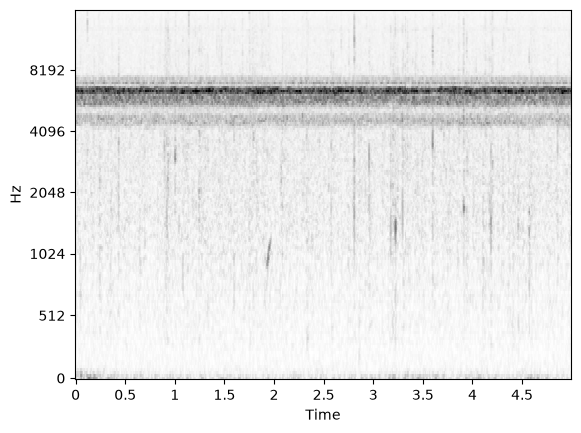

dataset name : SWIFT
source uri   : SWIFT29_2021-04-14/SWIFT29_20210414_181045.wav
offset_s     : 410.00
score        : 4.13


GridspecLayout(children=(Button(description='LEPINS', layout=Layout(grid_area='widget001'), style=ButtonStyle(…


--------------------------------------------------------------------------------


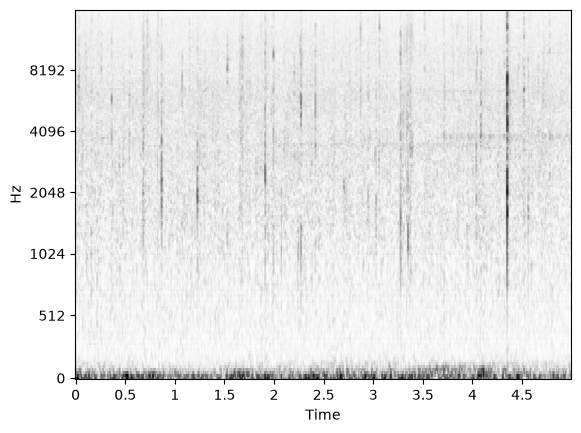

dataset name : SWIFT
source uri   : SWIFT29_2021-04-14/SWIFT29_20210414_155037.wav
offset_s     : 0.00
rank         : 1
score        : 3.44


GridspecLayout(children=(Button(description='LEPINS', layout=Layout(grid_area='widget001'), style=ButtonStyle(…


--------------------------------------------------------------------------------


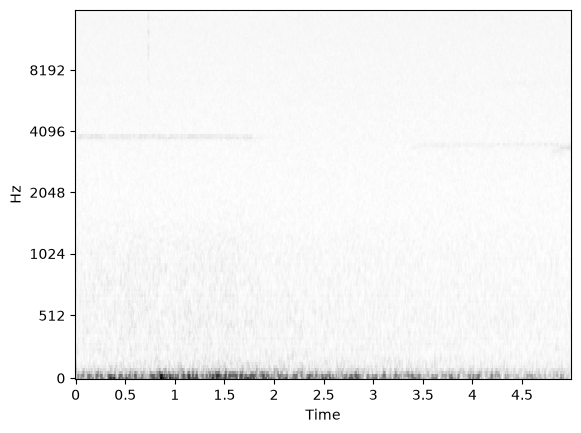

dataset name : SWIFT
source uri   : SWIFT29_2021-04-14/SWIFT29_20210414_085010.wav
offset_s     : 15.00
rank         : 2
score        : 3.43


GridspecLayout(children=(Button(description='LEPINS', layout=Layout(grid_area='widget001'), style=ButtonStyle(…


--------------------------------------------------------------------------------


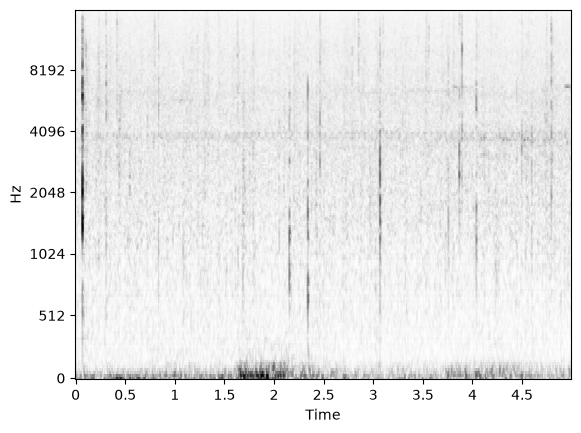

dataset name : SWIFT
source uri   : SWIFT29_2021-04-14/SWIFT29_20210414_154036.wav
offset_s     : 450.00
rank         : 3
score        : 3.39


GridspecLayout(children=(Button(description='LEPINS', layout=Layout(grid_area='widget001'), style=ButtonStyle(…


--------------------------------------------------------------------------------


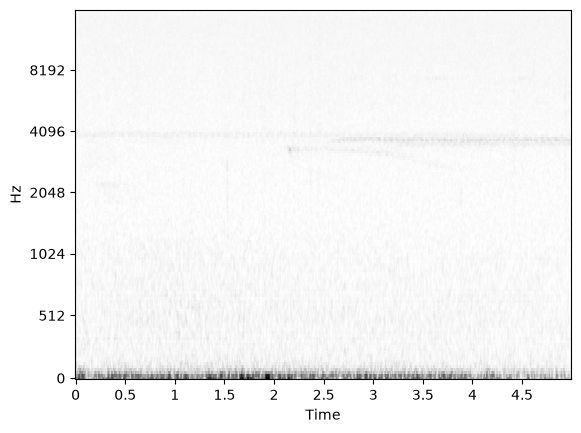

dataset name : SWIFT
source uri   : SWIFT29_2021-04-14/SWIFT29_20210414_100015.wav
offset_s     : 545.00
rank         : 4
score        : 3.37


GridspecLayout(children=(Button(description='LEPINS', layout=Layout(grid_area='widget001'), style=ButtonStyle(…


--------------------------------------------------------------------------------


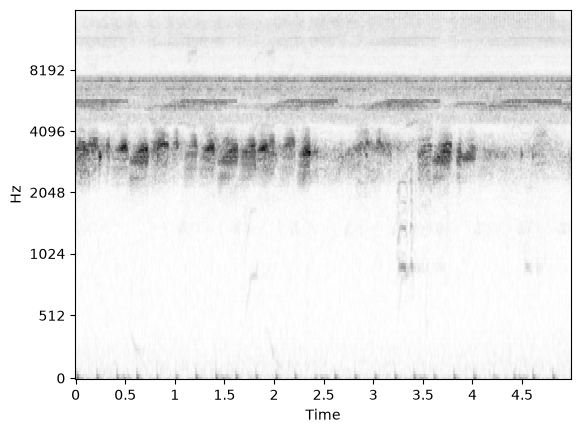

dataset name : grillos
source uri   : sw2/1Jsw2_20261006_230700.wav
offset_s     : 10.00
rank         : 5
score        : 3.32


GridspecLayout(children=(Button(description='LEPINS', layout=Layout(grid_area='widget001'), style=ButtonStyle(…


--------------------------------------------------------------------------------


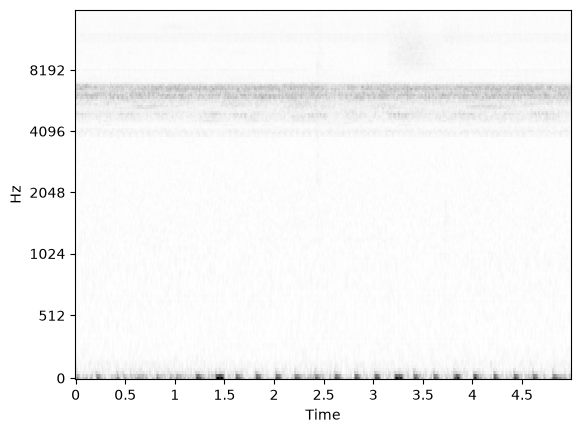

dataset name : grillos
source uri   : spto1/1Jspto1_20261018_030000.wav
offset_s     : 30.00
rank         : 6
score        : 3.30


GridspecLayout(children=(Button(description='LEPINS', layout=Layout(grid_area='widget001'), style=ButtonStyle(…


--------------------------------------------------------------------------------


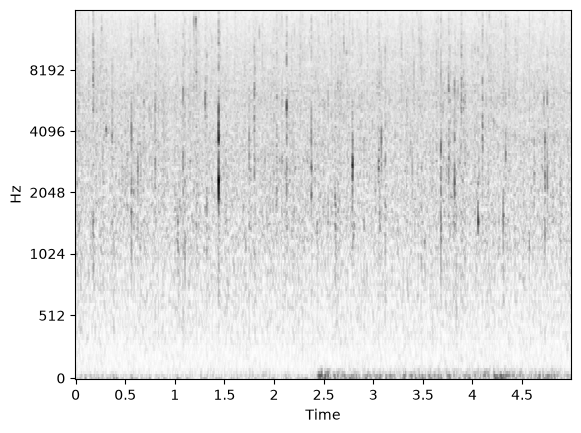

dataset name : SWIFT
source uri   : SWIFT29_2021-04-14/SWIFT29_20210414_170040.wav
offset_s     : 110.00
rank         : 7
score        : 3.30


GridspecLayout(children=(Button(description='LEPINS', layout=Layout(grid_area='widget001'), style=ButtonStyle(…


--------------------------------------------------------------------------------
Page 1 of 1


Button(description='Prev Page', style=ButtonStyle())

Button(description='Next Page', style=ButtonStyle())

In [10]:
# @title Display the search results for labeling {vertical-output: true}

display_results = embedding_display.EmbeddingDisplayGroup.from_search_results(
    filtered,
    db,
    sample_rate_hz=SAMPLE_RATE,
    frame_rate=100,
    audio_loader=audio_filepath_loader,
)
display_results.display(positive_labels=[target_label])

### Save your labels

This stores the labels you just applied in the database, tagged with your `annotator_id`, next to the embeddings they describe.

Run this **after** labeling the results above and **before** re-running the search — the widget is rebuilt each time you search, and any labels you have not saved are lost with it.

In [16]:
# @title Save the labels {vertical-output: true}

import collections

before = len(db.get_all_annotations())
new_labels = display_results.harvest_labels(annotator_id)

if not new_labels:
  print('NOTHING WAS SAVED - no results were labeled.\n')
  print('The label button cycles through four states as you click it:')
  print('    grey (no icon)  = unlabeled, ignored')
  print('    GREEN  (+)      = present   <-- click ONCE to get here')
  print('    orange (-)      = absent')
  print('    blue   (?)      = uncertain, deliberately skipped')
  print('    grey            = back to the start\n')
  print('Scroll up and click each button until it is GREEN with a + icon')
  print(f'on every clip where you hear the target species ({target_label}),')
  print('then run this cell again.\n')
  print('If none of the results genuinely contain the species, go back to')
  print('the search cell and try a different query window or a larger')
  print('num_results before labeling.')
else:
  db.insert_annotations(new_labels, handle_duplicates='skip')
  db.commit()
  after = len(db.get_all_annotations())

  kinds = collections.Counter(
      getattr(a.label_type, 'name', str(a.label_type)) for a in new_labels)
  print('Just labeled:')
  for kind, count in kinds.items():
    print(f'  {kind:10s} {count}')

  print(f'\nAnnotations before : {before}')
  print(f'Annotations after  : {after}')
  print(f'Newly saved        : {after - before}')

  print('\nTotal labels in the database:')
  for label, count in db.count_each_label().items():
    print(f'  {label:12s} {count}')

  n_target = db.count_each_label().get(target_label, 0)
  
  print(f'\n{n_target} labels for {target_label}')

Just labeled:
  POSITIVE   7
  NEGATIVE   16

Annotations before : 153
Annotations after  : 176
Newly saved        : 23

Total labels in the database:
  BOAROS       45
  DENEBR       42
  LEPINS       23
  PHYVIT       25
  SCIBOU       27

23 labels for LEPINS
